In [8]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
trr= pd.read_csv("globalterrorismdb_0718dist.csv",encoding='cp1252')

/var/folders/f9/l67h8nd12t17x69bp0ts13w00000gn/T/ipykernel_20521/603374382.py:5: DtypeWarning: Columns (4,6,31,33,61,62,63,76,79,90,92,94,96,114,115,121) have mixed types. Specify dtype option on import or set low_memory=False.
  trr= pd.read_csv("globalterrorismdb_0718dist.csv",encoding='cp1252')


In [10]:
print(trr.head())

        eventid  iyear  imonth  iday approxdate  extended resolution  country  \
0  197000000001   1970       7     2        NaN         0        NaN       58   
1  197000000002   1970       0     0        NaN         0        NaN      130   
2  197001000001   1970       1     0        NaN         0        NaN      160   
3  197001000002   1970       1     0        NaN         0        NaN       78   
4  197001000003   1970       1     0        NaN         0        NaN      101   

          country_txt  region  ... addnotes scite1 scite2  scite3  dbsource  \
0  Dominican Republic       2  ...      NaN    NaN    NaN     NaN      PGIS   
1              Mexico       1  ...      NaN    NaN    NaN     NaN      PGIS   
2         Philippines       5  ...      NaN    NaN    NaN     NaN      PGIS   
3              Greece       8  ...      NaN    NaN    NaN     NaN      PGIS   
4               Japan       4  ...      NaN    NaN    NaN     NaN      PGIS   

   INT_LOG  INT_IDEO INT_MISC INT_ANY 

In [11]:
print(trr.columns)


Index(['eventid', 'iyear', 'imonth', 'iday', 'approxdate', 'extended',
       'resolution', 'country', 'country_txt', 'region',
       ...
       'addnotes', 'scite1', 'scite2', 'scite3', 'dbsource', 'INT_LOG',
       'INT_IDEO', 'INT_MISC', 'INT_ANY', 'related'],
      dtype='object', length=135)


In [13]:
# Check structure
trr.shape  # (rows, columns)
trr.columns.tolist()[:10]  # Show some column names

# View basic info
trr.info()

# Check missing values
trr.isnull().sum().sort_values(ascending=False).head(20)

# Summary statistics
trr.describe(include='all')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181691 entries, 0 to 181690
Columns: 135 entries, eventid to related
dtypes: float64(55), int64(22), object(58)
memory usage: 187.1+ MB


,eventid,iyear,imonth,iday,approxdate,extended,resolution,country,country_txt,region,...,addnotes,scite1,scite2,scite3,dbsource,INT_LOG,INT_IDEO,INT_MISC,INT_ANY,related
count,1.816910e+05,181691.000000,181691.000000,181691.000000,9239,181691.000000,2220,181691.000000,181691,181691.000000,...,28289,115500,76933,43516,181691,181691.000000,181691.000000,181691.000000,181691.000000,25038
unique,NaN,NaN,NaN,NaN,2244,NaN,1859,NaN,205,NaN,...,15429,83988,62263,36090,26,NaN,NaN,NaN,NaN,14306
top,NaN,NaN,NaN,NaN,"September 18-24, 2016",NaN,8/4/1998,NaN,Iraq,NaN,...,Casualty numbers for this incident conflict ac...,Committee on Government Operations United Stat...,"Christopher Hewitt, ""Political Violence and Te...","Christopher Hewitt, ""Political Violence and Te...",START Primary Collection,NaN,NaN,NaN,NaN,"201612010023, 201612010024, 201612010025, 2016..."
freq,NaN,NaN,NaN,NaN,101,NaN,18,NaN,24636,NaN,...,1607,205,134,139,78002,NaN,NaN,NaN,NaN,80
mean,2.002705e+11,2002.638997,6.467277,15.505644,NaN,0.045346,NaN,131.968501,NaN,7.160938,...,NaN,NaN,NaN,NaN,NaN,-4.543731,-4.464398,0.090010,-3.945952,NaN
std,1.325957e+09,13.259430,3.388303,8.814045,NaN,0.208063,NaN,112.414535,NaN,2.933408,...,NaN,NaN,NaN,NaN,NaN,4.543547,4.637152,0.568457,4.691325,NaN
min,1.970000e+11,1970.000000,0.000000,0.000000,NaN,0.000000,NaN,4.000000,NaN,1.000000,...,NaN,NaN,NaN,NaN,NaN,-9.000000,-9.000000,-9.000000,-9.000000,NaN
25%,1.991021e+11,1991.000000,4.000000,8.000000,NaN,0.000000,NaN,78.000000,NaN,5.000000,...,NaN,NaN,NaN,NaN,NaN,-9.000000,-9.000000,0.000000,-9.000000,NaN
50%,2.009022e+11,2009.000000,6.000000,15.000000,NaN,0.000000,NaN,98.000000,NaN,6.000000,...,NaN,NaN,NaN,NaN,NaN,-9.000000,-9.000000,0.000000,0.000000,NaN
75%,2.014081e+11,2014.000000,9.000000,23.000000,NaN,0.000000,NaN,160.000000,NaN,10.000000,...,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,NaN


In [15]:
columns_to_keep = [
    'iyear', 'imonth', 'iday', 'country_txt', 'region_txt', 'city',
    'latitude', 'longitude', 'attacktype1_txt', 'targtype1_txt',
    'weaptype1_txt', 'nkill', 'nwound', 'gname', 'summary'
]

trr = trr[columns_to_keep]

In [17]:
# Instead of chained assignment with inplace=True, do this:
trr['nkill'] = trr['nkill'].fillna(0)
trr['nwound'] = trr['nwound'].fillna(0)
trr['summary'] = trr['summary'].fillna('Unknown')

# For other columns (careful with dtype!)
# Example: only apply 'Not specified' to object (text) columns
for col in trr.select_dtypes(include=['object']).columns:
    trr[col] = trr[col].fillna('Not specified')

In [18]:
# Total casualties
trr['casualties'] = trr['nkill'] + trr['nwound']

# Label major attacks
trr['major_attack'] = trr['casualties'].apply(lambda x: 1 if x >= 10 else 0)

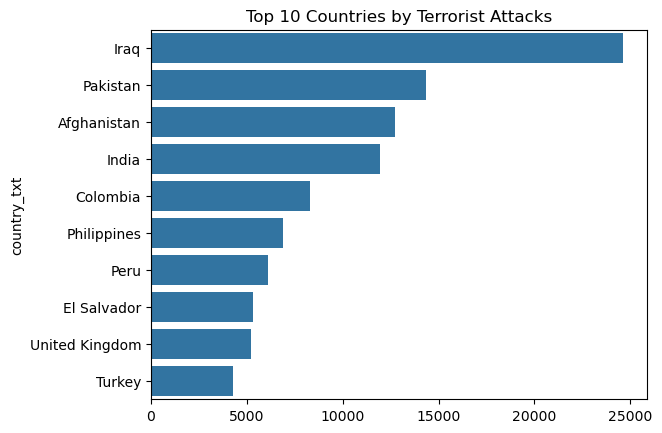

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Top 10 countries
top_countries = trr['country_txt'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Countries by Terrorist Attacks")
plt.show()

In [21]:
# Encode categorical variables
trr_ml = trr.copy()
categorical_cols = ['country_txt', 'region_txt', 'attacktype1_txt', 'targtype1_txt', 'weaptype1_txt', 'gname']
trr_ml = pd.get_dummies(trr_ml, columns=categorical_cols, drop_first=True)

# Drop text columns
trr_ml.drop(columns=['city', 'summary'], inplace=True)

# Check final shape
trr_ml.shape

(181691, 3800)

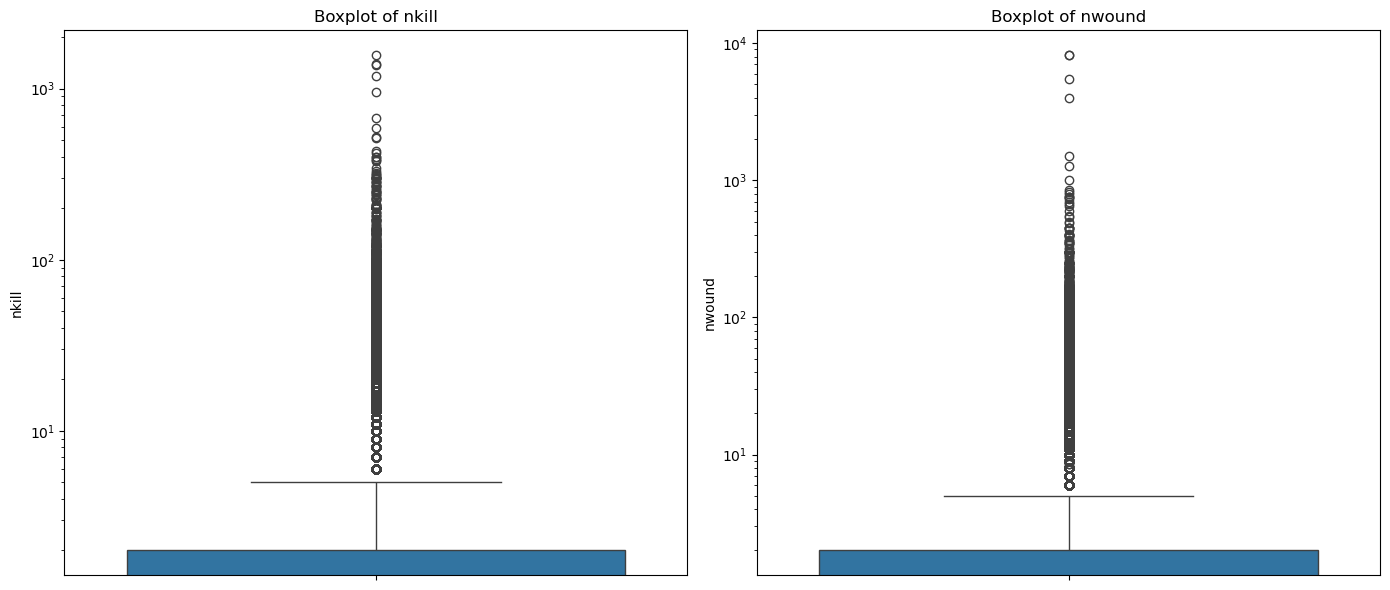

In [22]:

# Select key numerical columns
trr[['nkill', 'nwound']] = trr[['nkill', 'nwound']].fillna(0)

# Plot boxplots to check for outliers
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for i, col in enumerate(['nkill', 'nwound']):
    sns.boxplot(y=trr[col], ax=axes[i])
    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_yscale('log')  # Log scale helps visualize large outliers

plt.tight_layout()
plt.show()

In [24]:
trr_encoded = pd.get_dummies(trr, columns=['country_txt', 'region_txt', 'targtype1_txt', 'weaptype1_txt'], drop_first=True)
from sklearn.model_selection import train_test_split

# Define input (X) and output (y)
X = trr_encoded.drop(columns=['attacktype1_txt'])
y = trr_encoded['attacktype1_txt']  # This is a multi-class label

# Split into training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(trr_encoded, y, test_size=0.25, random_state=42, stratify=y)

# Train model
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)

print(f"Random Forest Accuracy: {rf_acc:.2f}")

Random Forest Accuracy: 0.86


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

In [29]:
# Print classification report
report = classification_report(y_test, rf_pred)
print("Classification Report:\n")
print(report)

Classification Report:

                                     precision    recall  f1-score   support

                      Armed Assault       0.79      0.84      0.82     10667
                      Assassination       0.71      0.56      0.62      4828
                  Bombing/Explosion       0.94      0.98      0.96     22064
     Facility/Infrastructure Attack       0.84      0.86      0.85      2589
                          Hijacking       0.66      0.27      0.39       165
Hostage Taking (Barricade Incident)       0.59      0.29      0.39       248
        Hostage Taking (Kidnapping)       0.67      0.56      0.61      2789
                    Unarmed Assault       0.69      0.58      0.63       254
                            Unknown       0.78      0.83      0.80      1819

                           accuracy                           0.86     45423
                          macro avg       0.74      0.64      0.67     45423
                       weighted avg       0.85    

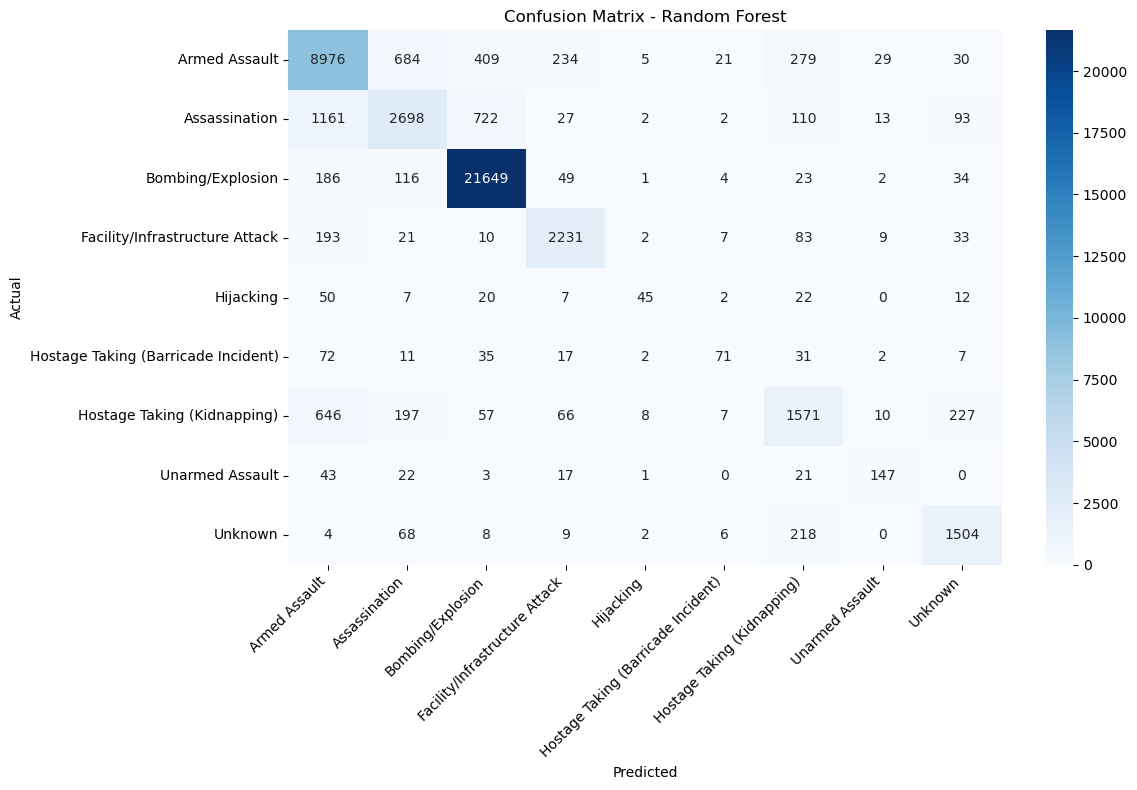

In [30]:
# Create confusion matrix
cm = confusion_matrix(y_test, rf_pred, labels=rf.classes_)

# Plot confusion matrix
plt.figure(figsize=(12, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=rf.classes_, yticklabels=rf.classes_)

plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

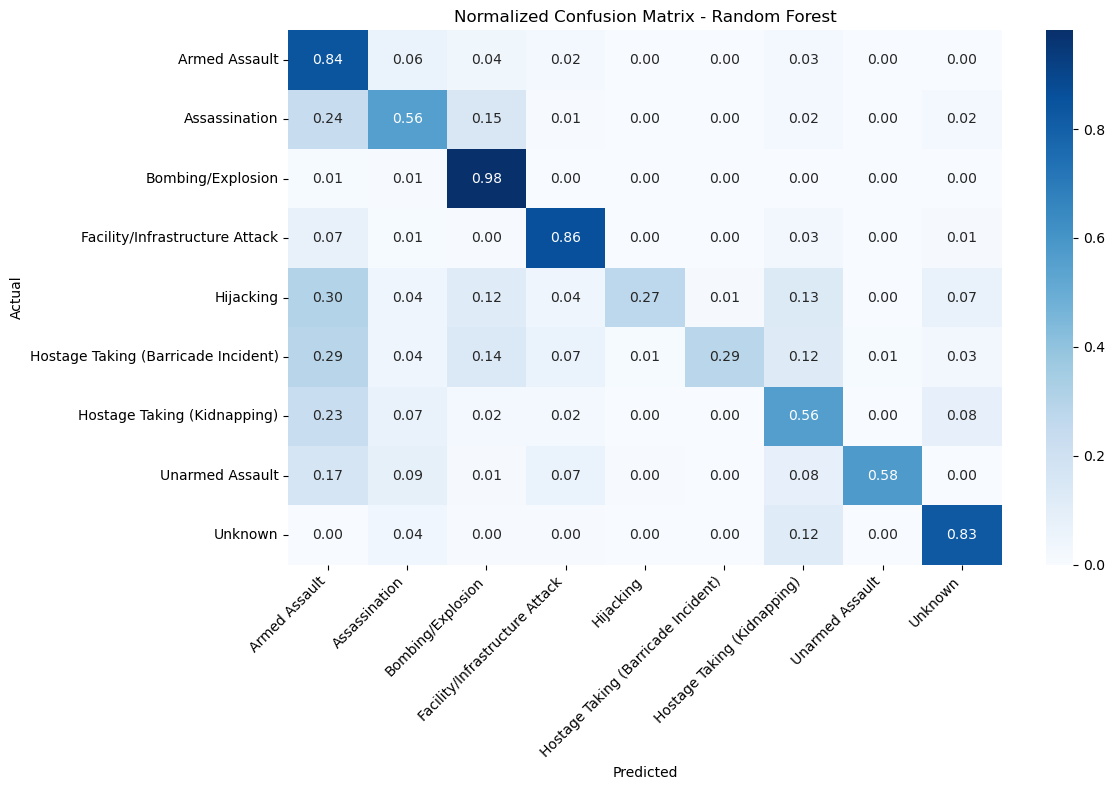

In [31]:
# Normalized Confusion Matrix
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(12, 8))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=rf.classes_, yticklabels=rf.classes_)

plt.title('Normalized Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [32]:
import pandas as pd

trr = pd.read_csv("globalterrorismdb_0718dist.csv", encoding='ISO-8859-1', low_memory=False)
print("Shape of the dataset:", trr.shape)
print("\nColumn names:", trr.columns.tolist())
trr.head()  # View first 5 rows

Shape of the dataset: (181691, 135)

Column names: ['eventid', 'iyear', 'imonth', 'iday', 'approxdate', 'extended', 'resolution', 'country', 'country_txt', 'region', 'region_txt', 'provstate', 'city', 'latitude', 'longitude', 'specificity', 'vicinity', 'location', 'summary', 'crit1', 'crit2', 'crit3', 'doubtterr', 'alternative', 'alternative_txt', 'multiple', 'success', 'suicide', 'attacktype1', 'attacktype1_txt', 'attacktype2', 'attacktype2_txt', 'attacktype3', 'attacktype3_txt', 'targtype1', 'targtype1_txt', 'targsubtype1', 'targsubtype1_txt', 'corp1', 'target1', 'natlty1', 'natlty1_txt', 'targtype2', 'targtype2_txt', 'targsubtype2', 'targsubtype2_txt', 'corp2', 'target2', 'natlty2', 'natlty2_txt', 'targtype3', 'targtype3_txt', 'targsubtype3', 'targsubtype3_txt', 'corp3', 'target3', 'natlty3', 'natlty3_txt', 'gname', 'gsubname', 'gname2', 'gsubname2', 'gname3', 'gsubname3', 'motive', 'guncertain1', 'guncertain2', 'guncertain3', 'individual', 'nperps', 'nperpcap', 'claimed', 'claimmod

,eventid,iyear,imonth,iday,approxdate,extended,resolution,country,country_txt,region,...,addnotes,scite1,scite2,scite3,dbsource,INT_LOG,INT_IDEO,INT_MISC,INT_ANY,related
0,197000000001,1970,7,2,NaN,0,NaN,58,Dominican Republic,2,...,NaN,NaN,NaN,NaN,PGIS,0,0,0,0,NaN
1,197000000002,1970,0,0,NaN,0,NaN,130,Mexico,1,...,NaN,NaN,NaN,NaN,PGIS,0,1,1,1,NaN
2,197001000001,1970,1,0,NaN,0,NaN,160,Philippines,5,...,NaN,NaN,NaN,NaN,PGIS,-9,-9,1,1,NaN
3,197001000002,1970,1,0,NaN,0,NaN,78,Greece,8,...,NaN,NaN,NaN,NaN,PGIS,-9,-9,1,1,NaN
4,197001000003,1970,1,0,NaN,0,NaN,101,Japan,4,...,NaN,NaN,NaN,NaN,PGIS,-9,-9,1,1,NaN


In [33]:
missing = trr.isnull().sum()
missing_percent = (missing / len(trr)) * 100
missing_data = pd.DataFrame({'Missing Values': missing, 'Percentage': missing_percent})
missing_data = missing_data[missing_data['Missing Values'] > 0].sort_values(by='Percentage', ascending=False)
missing_data.head(15)

,Missing Values,Percentage
gsubname3,181671,99.988992
weapsubtype4,181621,99.961473
weapsubtype4_txt,181621,99.961473
weaptype4,181618,99.959822
weaptype4_txt,181618,99.959822
claimmode3,181558,99.926799
claimmode3_txt,181558,99.926799
gsubname2,181531,99.911938
claim3,181373,99.824978
guncertain3,181371,99.823877


In [34]:
trr.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
eventid,181691.0,NaN,NaN,NaN,200270523949.245697,1325957057.163446,197000000001.0,199102060003.5,200902230001.0,201408090035.5,201712310032.0
iyear,181691.0,NaN,NaN,NaN,2002.638997,13.25943,1970.0,1991.0,2009.0,2014.0,2017.0
imonth,181691.0,NaN,NaN,NaN,6.467277,3.388303,0.0,4.0,6.0,9.0,12.0
iday,181691.0,NaN,NaN,NaN,15.505644,8.814045,0.0,8.0,15.0,23.0,31.0
approxdate,9239,2244,"September 18-24, 2016",101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
INT_LOG,181691.0,NaN,NaN,NaN,-4.543731,4.543547,-9.0,-9.0,-9.0,0.0,1.0
INT_IDEO,181691.0,NaN,NaN,NaN,-4.464398,4.637152,-9.0,-9.0,-9.0,0.0,1.0
INT_MISC,181691.0,NaN,NaN,NaN,0.09001,0.568457,-9.0,0.0,0.0,0.0,1.0
INT_ANY,181691.0,NaN,NaN,NaN,-3.945952,4.691325,-9.0,-9.0,0.0,0.0,1.0


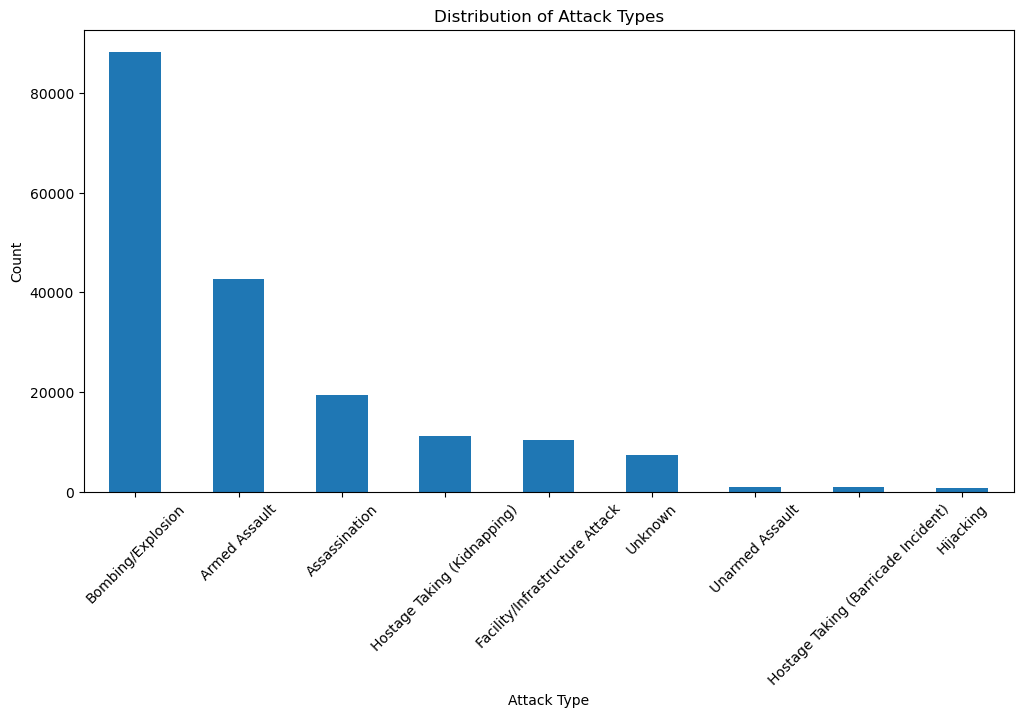

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))
trr['attacktype1_txt'].value_counts().plot(kind='bar')
plt.title('Distribution of Attack Types')
plt.xlabel('Attack Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

In [36]:
# Update path if needed
trr = pd.read_csv("globalterrorismdb_0718dist.csv", encoding='latin1', low_memory=False)

In [37]:
# Check unique countries to confirm the exact name if needed: trr['country_txt'].unique()
india_df = trr[trr['country_txt'] == 'India']

In [38]:
# Check if 'iyear' column exists and is clean
attacks_per_year = india_df.groupby('iyear').size().reset_index(name='attack_count')